# Test opponent-map display conversion
Set the HDF5 path and frame index below, then run all cells. Only the selected frame's normalization window is loaded. The plots compare the original signed channel values with the uint8 display values; these are not natural RGB colors.

Uses Geoff's [rolling-window instructions](https://upennvisionlabs.slack.com/archives/C08D870F54P/p1793712750563809).

In [1]:
from pathlib import Path
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / "code/library/sensor_utility/world_util.py").exists())
sys.path.insert(0, str(project_root / "code/library/sensor_utility"))
import world_util


In [4]:
hdf5_path = Path("/Volumes/FLIC_processing/NEWscriptedIndoorOutdoorVideos2026/FLIC_20/walkOutdoor/GKA/1/W/transformed.hdf5")
raw_chunks_path = Path("/path/to/raw/chunks")  # Set the directory containing world and MS chunks.
frame_index = 0
channel = 0  # 0: L+M; 1: L-M; 2: S
fps = 120.0  # Input recording rate, not the playback rate
window_seconds = 1.0


In [ ]:
import sensors_utility

# The world file lives in W; its parent recording also contains M.
recording_directory = hdf5_path.expanduser().parent.parent
recording_figure, recording_axes = sensors_utility.plot_processed_recording(
    str(recording_directory), verbose=True
)
plt.show()


In [ ]:
# Plot the raw world and MS chunks with progress reporting.
raw_figure, raw_axes = sensors_utility.plot_raw_recording(
    str(raw_chunks_path.expanduser()), verbose=True
)
plt.show()


In [5]:
with h5py.File(hdf5_path.expanduser(), "r") as saved:
    frames = saved["data/frames"]
    assert 0 <= frame_index < len(frames), "frame_index is outside the recording."
    assert 0 <= channel < frames.shape[-1]
    window_frames = min(len(frames), max(1, int(round(fps * window_seconds))))
    start = min(max(frame_index - window_frames // 2, 0), len(frames) - window_frames)
    opponentmaps = frames[start:start + window_frames]

converted_frames = world_util.opponentmap_to_videoframe(
    opponentmaps, fps=fps, window_seconds=window_seconds
)
selected = frame_index - start
before = opponentmaps[selected, ..., channel]
after = converted_frames[selected, ..., channel]
print(f"Loaded frames {start}:{start + window_frames}; output {converted_frames.shape}, {converted_frames.dtype}")


Loaded frames 0:120; output (120, 361, 361, 3), uint8


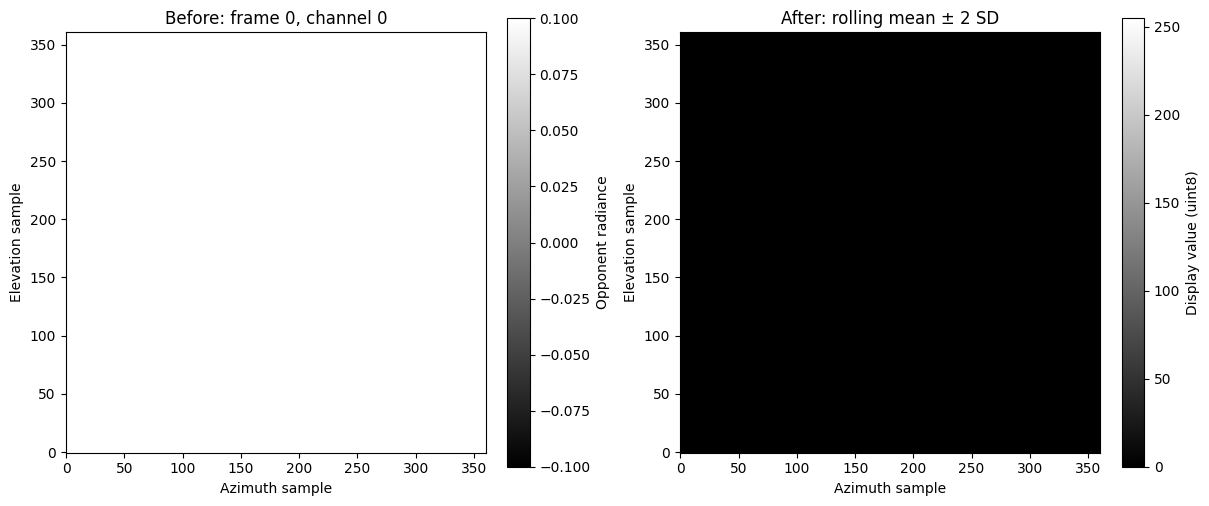

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
# Transpose both arrays to place azimuth horizontally and elevation vertically.
raw_image = axes[0].imshow(np.ma.masked_invalid(before.T), origin="lower", cmap="gray")
axes[0].set_title(f"Before: frame {frame_index}, channel {channel}")
fig.colorbar(raw_image, ax=axes[0], label="Opponent radiance")
converted_image = axes[1].imshow(after.T, origin="lower", cmap="gray", vmin=0, vmax=255)
axes[1].set_title("After: rolling mean ± 2 SD")
fig.colorbar(converted_image, ax=axes[1], label="Display value (uint8)")
for axis in axes:
    axis.set_xlabel("Azimuth sample")
    axis.set_ylabel("Elevation sample")
plt.show()
